# Lab 7 — Vision Transformer (ViT) on CIFAR-10This notebook implements a **Vision Transformer from scratch** and trains it to classify images from the CIFAR-10 dataset (10 classes, 32x32 RGB images).**Pipeline overview:**1. Load and augment the CIFAR-10 dataset2. Build ViT components: patch embedding, multi-head self-attention, Transformer blocks3. Assemble the full `VisionTransformer` model4. Train with AdamW + cosine LR annealing5. Evaluate with accuracy curves, confusion matrix, per-class accuracy, and qualitative predictions## 1. Setup — install packages and import libraries

In [ ]:
# Install if needed
!pip install torch torchvision einops timm

# Core deep learning framework
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

# Dataset utilities and image transforms
import torchvision
import torchvision.transforms as transforms

# einops gives us a readable way to reshape tensors (used in patch embedding)
from einops import rearrange

# Plotting and numerical utilities
import matplotlib.pyplot as plt
import numpy as np


## 2. Data loading and augmentationDownload CIFAR-10, apply normalization/augmentation, and wrap it in `DataLoader`s for batched training.

In [ ]:
# --- Hyperparameters & data setup ---
IMG_SIZE = 32       # CIFAR-10 images are 32x32
PATCH_SIZE = 4       # each image is split into 4x4 patches -> (32/4)^2 = 64 patches
BATCH_SIZE = 128
NUM_CLASSES = 10

# Training transforms include light augmentation (flip + random crop) to reduce overfitting
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),   # per-channel mean (CIFAR-10 stats)
                         (0.2470, 0.2435, 0.2616)),   # per-channel std
])

# Test transforms only normalize -- no augmentation, so evaluation is deterministic
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.4914, 0.4822, 0.4465),
                         (0.2470, 0.2435, 0.2616)),
])

# Download (if needed) and load the CIFAR-10 train/test splits
train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                              download=True, transform=train_transform)
test_dataset  = torchvision.datasets.CIFAR10(root='./data', train=False,
                                              download=True, transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

# Human-readable class names, indexed to match CIFAR-10's integer labels
classes = ['airplane','automobile','bird','cat','deer',
           'dog','frog','horse','ship','truck']


100%|██████████| 170M/170M [00:19<00:00, 8.70MB/s]


## 3. Model architectureDefine the ViT building blocks: patch embedding (image → sequence of patch tokens), multi-head self-attention, a Transformer encoder block, and the full `VisionTransformer` that ties them together with a `[CLS]` token and learnable positional embeddings.

In [ ]:
# --- Vision Transformer (ViT) building blocks ---

class PatchEmbedding(nn.Module):
    """Splits an image into fixed-size patches and linearly projects each
    patch into an embedding vector (this is the ViT equivalent of tokenizing text)."""
    def __init__(self, img_size=32, patch_size=4, in_channels=3, embed_dim=128):
        super().__init__()
        self.num_patches = (img_size // patch_size) ** 2
        # A single strided conv does the "split into patches + linear projection" in one step:
        # each kernel_size x kernel_size patch is projected to embed_dim, non-overlapping (stride=patch_size)
        self.proj = nn.Conv2d(in_channels, embed_dim,
                              kernel_size=patch_size, stride=patch_size)

    def forward(self, x):
        x = self.proj(x)                        # (B, embed_dim, H', W')
        x = rearrange(x, 'b e h w -> b (h w) e') # flatten spatial grid into a sequence of patch tokens: (B, num_patches, embed_dim)
        return x


class MultiHeadSelfAttention(nn.Module):
    """Standard multi-head self-attention with a residual connection and post-norm."""
    def __init__(self, embed_dim, num_heads, dropout=0.1):
        super().__init__()
        self.attn = nn.MultiheadAttention(embed_dim, num_heads,
                                          dropout=dropout, batch_first=True)
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x):
        attn_out, _ = self.attn(x, x, x)  # self-attention: query = key = value = x
        return self.norm(x + attn_out)    # residual connection followed by LayerNorm


class TransformerBlock(nn.Module):
    """One Transformer encoder block: self-attention followed by a feed-forward MLP,
    each wrapped with a residual connection."""
    def __init__(self, embed_dim, num_heads, mlp_ratio=4, dropout=0.1):
        super().__init__()
        self.attn = MultiHeadSelfAttention(embed_dim, num_heads, dropout)
        # Feed-forward network expands then projects back down (mlp_ratio controls the expansion factor)
        self.ffn = nn.Sequential(
            nn.LayerNorm(embed_dim),
            nn.Linear(embed_dim, embed_dim * mlp_ratio),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(embed_dim * mlp_ratio, embed_dim),
            nn.Dropout(dropout),
        )
        self.norm = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = self.attn(x)
        x = self.norm(x + self.ffn(x))   # residual connection around the FFN
        return x


class VisionTransformer(nn.Module):
    """Full ViT: patch embedding -> [CLS] token + positional embeddings ->
    stack of Transformer blocks -> classification head on the [CLS] token."""
    def __init__(self, img_size=32, patch_size=4, in_channels=3,
                 num_classes=10, embed_dim=128, depth=6,
                 num_heads=8, mlp_ratio=4, dropout=0.1):
        super().__init__()
        self.patch_embed = PatchEmbedding(img_size, patch_size, in_channels, embed_dim)
        num_patches = self.patch_embed.num_patches

        # Learnable [CLS] token prepended to the patch sequence; its final representation
        # is used for classification (borrowed from BERT-style architectures)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        # Learnable positional embeddings since attention itself has no notion of order/position
        self.pos_embed = nn.Parameter(torch.zeros(1, num_patches + 1, embed_dim))
        self.dropout   = nn.Dropout(dropout)

        # Stack `depth` Transformer encoder blocks
        self.transformer = nn.Sequential(*[
            TransformerBlock(embed_dim, num_heads, mlp_ratio, dropout)
            for _ in range(depth)
        ])

        self.norm      = nn.LayerNorm(embed_dim)
        self.head      = nn.Linear(embed_dim, num_classes)  # final classification layer

    def forward(self, x):
        B = x.size(0)
        x = self.patch_embed(x)                          # (B, N, D) patch tokens
        cls = self.cls_token.expand(B, -1, -1)           # (B, 1, D) broadcast CLS token to batch
        x   = torch.cat([cls, x], dim=1)                 # (B, N+1, D) prepend CLS token
        x   = self.dropout(x + self.pos_embed)           # add positional info
        x   = self.transformer(x)                        # pass through Transformer encoder stack
        x   = self.norm(x[:, 0])                         # take only the CLS token's output representation
        return self.head(x)                              # project to class logits


## 4. Instantiate model, loss, optimizer, and LR scheduler

In [ ]:
# --- Model, loss, and optimizer setup ---
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

model = VisionTransformer(
    img_size=32, patch_size=4, embed_dim=128,
    depth=6, num_heads=8, num_classes=10
).to(device)

criterion = nn.CrossEntropyLoss()
# AdamW with weight decay for regularization -- standard choice for training Transformers
optimizer = optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.05)
# Cosine annealing smoothly decays the learning rate to 0 over T_max epochs
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=30)

print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")


Using device: cuda
Parameters: 1,207,434


## 5. Train the modelRun the training loop for 30 epochs, tracking loss/accuracy on both the train and validation (test) sets each epoch.

In [ ]:
# --- Training and evaluation loops ---

def train_epoch(model, loader, optimizer, criterion, device):
    """Runs one full pass over the training set, updating model weights."""
    model.train()
    total_loss, correct, total = 0, 0, 0
    for imgs, labels in loader:
        imgs, labels = imgs.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        # Gradient clipping helps stabilize Transformer training
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        total_loss += loss.item()
        correct += (outputs.argmax(1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / len(loader), 100 * correct / total


def evaluate(model, loader, criterion, device):
    """Runs inference over the given loader without updating weights, for validation/testing."""
    model.eval()
    total_loss, correct, total = 0, 0, 0
    with torch.no_grad():  # disable gradient tracking to save memory/compute during eval
        for imgs, labels in loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            total_loss += criterion(outputs, labels).item()
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / len(loader), 100 * correct / total


EPOCHS = 30
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

# --- Main training loop ---
for epoch in range(1, EPOCHS + 1):
    tr_loss, tr_acc = train_epoch(model, train_loader, optimizer, criterion, device)
    va_loss, va_acc = evaluate(model, test_loader, criterion, device)
    scheduler.step()  # advance the cosine LR schedule by one epoch

    history['train_loss'].append(tr_loss)
    history['train_acc'].append(tr_acc)
    history['val_loss'].append(va_loss)
    history['val_acc'].append(va_acc)

    # Only print every 5 epochs to keep the output compact
    if epoch % 5 == 0:
        print(f"Epoch {epoch:3d}/{EPOCHS} | "
              f"Train Loss: {tr_loss:.4f} Acc: {tr_acc:.2f}% | "
              f"Val Loss: {va_loss:.4f} Acc: {va_acc:.2f}%")


Epoch   5/30 | Train Loss: 1.1208 Acc: 59.75% | Val Loss: 1.0333 Acc: 62.74%
Epoch  10/30 | Train Loss: 0.9058 Acc: 67.56% | Val Loss: 0.8368 Acc: 70.35%
Epoch  15/30 | Train Loss: 0.7674 Acc: 72.77% | Val Loss: 0.7336 Acc: 74.10%
Epoch  20/30 | Train Loss: 0.6726 Acc: 76.17% | Val Loss: 0.6730 Acc: 76.47%
Epoch  25/30 | Train Loss: 0.6213 Acc: 77.97% | Val Loss: 0.6541 Acc: 77.56%
Epoch  30/30 | Train Loss: 0.5980 Acc: 78.83% | Val Loss: 0.6488 Acc: 77.77%


## 6. Training curvesPlot loss and accuracy over epochs to check for overfitting/underfitting and see where validation performance peaked.

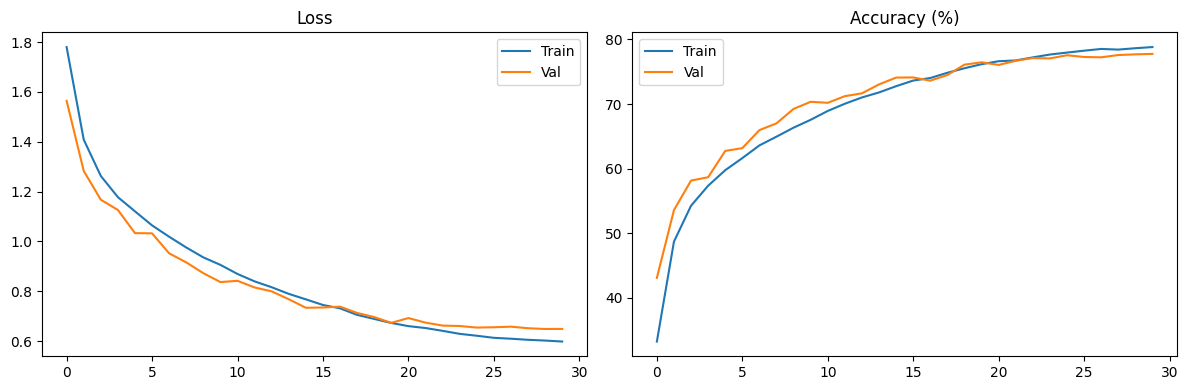

Best Val Accuracy: 77.77%


In [ ]:
# --- Plot training curves ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history['train_loss'], label='Train')
axes[0].plot(history['val_loss'],   label='Val')
axes[0].set_title('Loss'); axes[0].legend()

axes[1].plot(history['train_acc'], label='Train')
axes[1].plot(history['val_acc'],   label='Val')
axes[1].set_title('Accuracy (%)'); axes[1].legend()

plt.tight_layout()
plt.show()
print(f"Best Val Accuracy: {max(history['val_acc']):.2f}%")


## 7. Confusion matrixSee which classes the model confuses with each other on the full test set.

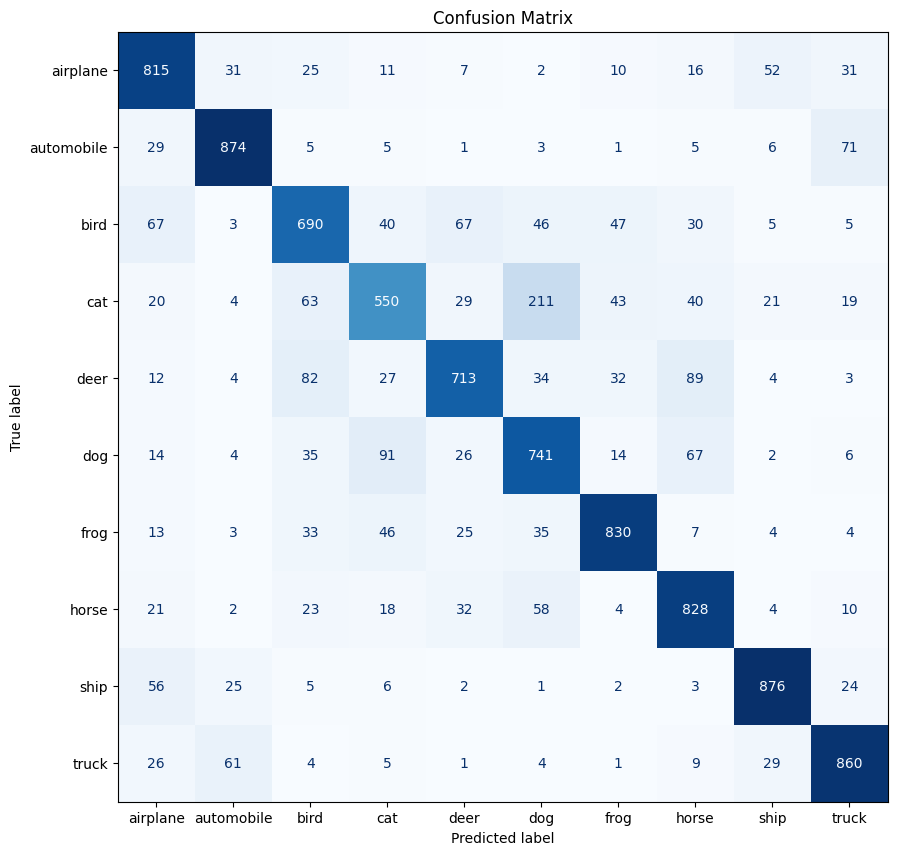

In [ ]:
# --- Confusion matrix on the test set ---
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

all_preds, all_labels = [], []
model.eval()
with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        preds = model(imgs).argmax(1).cpu()
        all_preds.extend(preds); all_labels.extend(labels)

# Rows = true class, columns = predicted class; diagonal = correct predictions
cm = confusion_matrix(all_labels, all_preds)
disp = ConfusionMatrixDisplay(cm, display_labels=classes)
fig, ax = plt.subplots(figsize=(10,10))
disp.plot(ax=ax, colorbar=False, cmap='Blues')
plt.title("Confusion Matrix"); plt.show()


## 8. Per-class accuracyBreak down accuracy by class to spot which categories are hardest for the model.

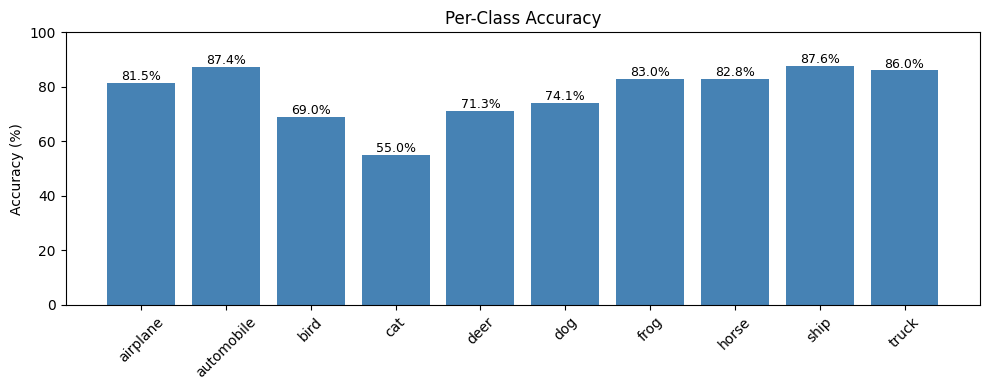

In [ ]:
# --- Per-class accuracy bar chart ---
# Normalize each row of the confusion matrix by its total to get per-class recall/accuracy
per_class = cm.diagonal() / cm.sum(axis=1) * 100
plt.figure(figsize=(10,4))
plt.bar(classes, per_class, color='steelblue')
plt.ylabel("Accuracy (%)"); plt.title("Per-Class Accuracy")
plt.xticks(rotation=45); plt.ylim(0, 100)
for i, v in enumerate(per_class):
    plt.text(i, v+1, f"{v:.1f}%", ha='center', fontsize=9)  # annotate each bar with its value
plt.tight_layout(); plt.show()


## 9. Qualitative predictionsVisually inspect a batch of test images with predicted vs. actual labels.

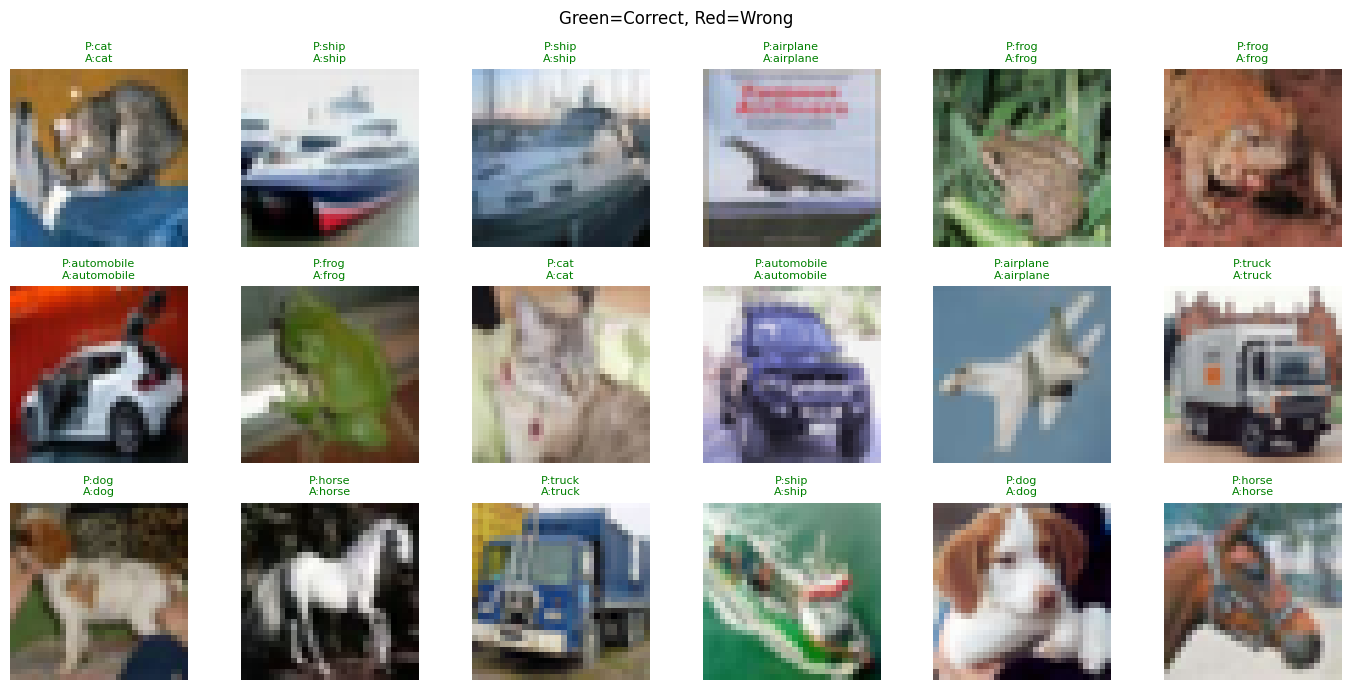

In [ ]:
# --- Visualize a batch of predictions (correct = green, wrong = red) ---
imgs, labels = next(iter(test_loader))
with torch.no_grad():
    preds = model(imgs.to(device)).argmax(1).cpu()

fig, axes = plt.subplots(3, 6, figsize=(14, 7))
for i, ax in enumerate(axes.flat):
    img = imgs[i].permute(1,2,0).numpy()               # CHW -> HWC for imshow
    # Undo normalization to get back displayable pixel values
    img = img * np.array([0.247,0.243,0.261]) + np.array([0.491,0.482,0.446])
    ax.imshow(np.clip(img, 0, 1))
    color = 'green' if preds[i]==labels[i] else 'red'
    ax.set_title(f"P:{classes[preds[i]]}\nA:{classes[labels[i]]}",
                 color=color, fontsize=8)
    ax.axis('off')
plt.suptitle("Green=Correct, Red=Wrong"); plt.tight_layout(); plt.show()


## 10. Learning rate schedule checkPlot the cosine annealing curve used during training, independent of the trained model, as a sanity check on the schedule shape.

/tmp/ipython-input-1494/1321109074.py:6: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  temp_sched.step()


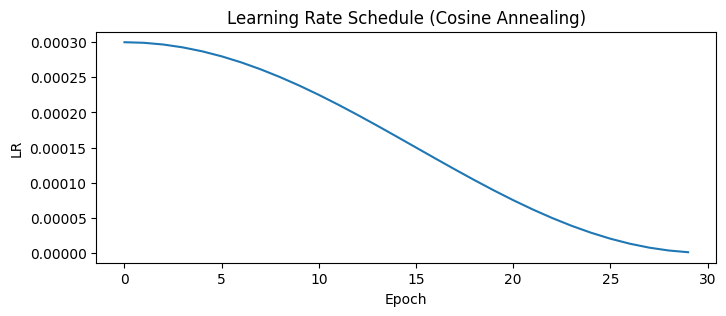

In [ ]:
# --- Sanity-check plot of the cosine annealing LR schedule ---
# Re-instantiate a throwaway optimizer/scheduler pair just to trace out the LR curve
lrs = []
temp_sched = optim.lr_scheduler.CosineAnnealingLR(
    optim.AdamW(model.parameters(), lr=3e-4), T_max=30)
for _ in range(30):
    lrs.append(temp_sched.get_last_lr()[0])
    temp_sched.step()

plt.figure(figsize=(8,3))
plt.plot(lrs); plt.title("Learning Rate Schedule (Cosine Annealing)")
plt.xlabel("Epoch"); plt.ylabel("LR"); plt.show()


## 11. Classification reportPrecision, recall, and F1-score per class, plus overall accuracy.

In [ ]:
# --- Full precision / recall / F1 report per class ---
from sklearn.metrics import classification_report
print(classification_report(all_labels, all_preds, target_names=classes))


              precision    recall  f1-score   support

    airplane       0.76      0.81      0.79      1000
  automobile       0.86      0.87      0.87      1000
        bird       0.72      0.69      0.70      1000
         cat       0.69      0.55      0.61      1000
        deer       0.79      0.71      0.75      1000
         dog       0.65      0.74      0.69      1000
        frog       0.84      0.83      0.84      1000
       horse       0.76      0.83      0.79      1000
        ship       0.87      0.88      0.87      1000
       truck       0.83      0.86      0.85      1000

    accuracy                           0.78     10000
   macro avg       0.78      0.78      0.78     10000
weighted avg       0.78      0.78      0.78     10000

